# VoxCeleb1 Speaker Classification Training (GPU/CUDA)
This notebook trains a VGG16-Lite CNN on pre-extracted spectrograms using GPU (CUDA). Training on GPU is faster than CPU training.

## 1. Setup & Imports

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import os
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
from collections import Counter
import json
import time

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Training device: GPU (CUDA)")
else:
    print(f"Training device: CPU (CUDA not available)")

PyTorch version: 2.8.0+cu129
CUDA available: True
Training device: GPU (CUDA)


## 2. Device Setup (GPU/CUDA Training)

In [7]:
# Use GPU/CUDA for training if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

Using device: cuda
GPU Name: NVIDIA GeForce RTX 4070 Laptop GPU
GPU Memory: 8.00 GB


## 3. Configuration

In [8]:
# Training configuration
CONFIG = {
    'data_dir': 'Spectograms',
    'batch_size': 96,  # Adjust based on GPU memory (32GB RAM + RTX 4070)
    'num_epochs': 50,
    'learning_rate': 0.0001,
    'dropout': 0.5,
    'train_split': 0.8,
    'random_seed': 42,
    'num_workers': 0,  # Use multiple workers for faster data loading on GPU
    'model_save_path': 'voxceleb_cnn_lite_gpu.pth',
    'use_class_percentage': 0.5,  # Use 50% of classes
    'target_size': (256, 256),  # Spectrogram size
    'early_stopping_patience': 7  # Stop if no improvement for 7 epochs
}

# Set random seeds for reproducibility
torch.manual_seed(CONFIG['random_seed'])
np.random.seed(CONFIG['random_seed'])
if torch.cuda.is_available():
    torch.cuda.manual_seed(CONFIG['random_seed'])
    torch.cuda.manual_seed_all(CONFIG['random_seed'])

print("Configuration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")

Configuration:
  data_dir: Spectograms
  batch_size: 96
  num_epochs: 50
  learning_rate: 0.0001
  dropout: 0.5
  train_split: 0.8
  random_seed: 42
  num_workers: 0
  model_save_path: voxceleb_cnn_lite_gpu.pth
  use_class_percentage: 0.5
  target_size: (256, 256)
  early_stopping_patience: 7


## 4. Data Augmentation for Spectrograms

In [9]:
class SpectrogramAugmentation:
    """
    Data augmentation techniques specifically designed for spectrograms
    """
    
    def __init__(self, 
                 freq_mask_param=30,  # Frequency masking width
                 time_mask_param=30,  # Time masking width
                 num_masks=2,         # Number of masks to apply
                 noise_std=0.01):     # Gaussian noise std
        self.freq_mask_param = freq_mask_param
        self.time_mask_param = time_mask_param
        self.num_masks = num_masks
        self.noise_std = noise_std
    
    def __call__(self, spectrogram):
        """
        Apply augmentations to spectrogram tensor [C, H, W]
        """
        spec = spectrogram.clone()
        
        # 1. SpecAugment: Frequency Masking
        for _ in range(self.num_masks):
            if torch.rand(1).item() > 0.5:
                freq_mask_width = torch.randint(0, self.freq_mask_param, (1,)).item()
                freq_start = torch.randint(0, max(1, spec.shape[1] - freq_mask_width), (1,)).item()
                spec[:, freq_start:freq_start + freq_mask_width, :] = 0
        
        # 2. SpecAugment: Time Masking
        for _ in range(self.num_masks):
            if torch.rand(1).item() > 0.5:
                time_mask_width = torch.randint(0, self.time_mask_param, (1,)).item()
                time_start = torch.randint(0, max(1, spec.shape[2] - time_mask_width), (1,)).item()
                spec[:, :, time_start:time_start + time_mask_width] = 0
        
        # 3. Random Gaussian Noise
        if torch.rand(1).item() > 0.5:
            noise = torch.randn_like(spec) * self.noise_std
            spec = torch.clamp(spec + noise, 0, 1)
        
        # 4. Random Time Shift (circular shift along time axis)
        if torch.rand(1).item() > 0.5:
            shift = torch.randint(-20, 20, (1,)).item()
            spec = torch.roll(spec, shifts=shift, dims=2)
        
        return spec

print("Spectrogram augmentation class defined")

Spectrogram augmentation class defined


## 5. Dataset Class

In [10]:
class SpectrogramDataset(Dataset):
    """Dataset for loading pre-extracted spectrogram .npy files"""
    
    def __init__(self, file_paths, labels, target_size=(256, 256), transform=None):
        """
        Args:
            file_paths: List of paths to .npy files
            labels: List of corresponding class labels
            target_size: Tuple (height, width) to resize spectrograms to
            transform: Optional transforms to apply
        """
        self.file_paths = file_paths
        self.labels = labels
        self.target_size = target_size
        self.transform = transform
        
    def __len__(self):
        return len(self.file_paths)
    
    def __getitem__(self, idx):
        # Load spectrogram from .npy file
        spectrogram = np.load(self.file_paths[idx])
        
        # Ensure 2D spectrogram
        if spectrogram.ndim == 1:
            # If 1D, reshape to square-ish 2D
            size = int(np.sqrt(len(spectrogram)))
            spectrogram = spectrogram[:size*size].reshape(size, size)
        
        # Convert to tensor and add channel dimension [C, H, W]
        spectrogram = torch.FloatTensor(spectrogram).unsqueeze(0)
        
        # Normalize to [0, 1] range
        if spectrogram.max() > spectrogram.min():
            spectrogram = (spectrogram - spectrogram.min()) / (spectrogram.max() - spectrogram.min())
        
        # Resize to fixed size using interpolation
        if spectrogram.shape[1:] != self.target_size:
            spectrogram = F.interpolate(
                spectrogram.unsqueeze(0),  # Add batch dimension [1, C, H, W]
                size=self.target_size,
                mode='bilinear',
                align_corners=False
            ).squeeze(0)  # Remove batch dimension [C, H, W]
        
        # Apply transforms if any
        if self.transform:
            spectrogram = self.transform(spectrogram)
        
        label = self.labels[idx]
        
        return spectrogram, label

## 6. Data Loading and Preparation

In [11]:
def load_dataset_metadata(data_dir, use_percentage=0.5):
    """
    Scan the Spectograms directory and collect file paths with labels.
    Uses only the first 50% of classes (speaker IDs).
    
    Args:
        data_dir: Root directory containing speaker ID subdirectories
        use_percentage: Percentage of classes to use (0.5 = 50%)
    
    Returns:
        file_paths: List of paths to .npy files
        labels: List of integer labels
        class_to_idx: Dictionary mapping speaker ID to integer label
    """
    data_path = Path(data_dir)
    
    if not data_path.exists():
        raise FileNotFoundError(f"Data directory not found: {data_dir}")
    
    # Get all speaker directories (class folders)
    all_speaker_dirs = sorted([d for d in data_path.iterdir() if d.is_dir()])
    
    # Use only first 50% of classes
    num_classes_to_use = max(1, int(len(all_speaker_dirs) * use_percentage))
    speaker_dirs = all_speaker_dirs[:num_classes_to_use]
    
    print(f"Total speaker classes available: {len(all_speaker_dirs)}")
    print(f"Using {num_classes_to_use} classes ({use_percentage*100}%)")
    
    # Create class mapping
    class_to_idx = {speaker_dir.name: idx for idx, speaker_dir in enumerate(speaker_dirs)}
    
    file_paths = []
    labels = []
    
    # Collect all .npy files
    for speaker_dir in tqdm(speaker_dirs, desc="Loading dataset metadata"):
        speaker_id = speaker_dir.name
        label = class_to_idx[speaker_id]
        
        # Find all .npy files in this speaker's directory
        npy_files = list(speaker_dir.glob('**/*.npy'))
        
        for npy_file in npy_files:
            file_paths.append(str(npy_file))
            labels.append(label)
    
    print(f"\nDataset statistics:")
    print(f"  Total samples: {len(file_paths)}")
    print(f"  Number of classes: {len(class_to_idx)}")
    print(f"  Samples per class (avg): {len(file_paths) / len(class_to_idx):.1f}")
    
    return file_paths, labels, class_to_idx

# Load dataset
file_paths, labels, class_to_idx = load_dataset_metadata(
    CONFIG['data_dir'], 
    use_percentage=CONFIG['use_class_percentage']
)

# Save class mapping for later use
with open('class_to_idx.json', 'w') as f:
    json.dump(class_to_idx, f, indent=2)
print(f"\nClass mapping saved to class_to_idx.json")

Total speaker classes available: 1211
Using 605 classes (50.0%)


Loading dataset metadata:   0%|          | 0/605 [00:00<?, ?it/s]


Dataset statistics:
  Total samples: 72766
  Number of classes: 605
  Samples per class (avg): 120.3

Class mapping saved to class_to_idx.json


## 7. Train/Validation Split (Stratified)

In [12]:
# Perform stratified split to maintain class distribution
train_paths, val_paths, train_labels, val_labels = train_test_split(
    file_paths,
    labels,
    test_size=(1 - CONFIG['train_split']),
    random_state=CONFIG['random_seed'],
    stratify=labels  # Stratified sampling
)

print(f"Training samples: {len(train_paths)}")
print(f"Validation samples: {len(val_paths)}")
print(f"\nClass distribution in training set:")
train_label_counts = Counter(train_labels)
print(f"  Min samples per class: {min(train_label_counts.values())}")
print(f"  Max samples per class: {max(train_label_counts.values())}")
print(f"  Avg samples per class: {np.mean(list(train_label_counts.values())):.1f}")

Training samples: 58212
Validation samples: 14554

Class distribution in training set:
  Min samples per class: 36
  Max samples per class: 525
  Avg samples per class: 96.2


## 8. Create DataLoaders with Augmentation

In [13]:
# Create augmentation (only for training)
train_augmentation = SpectrogramAugmentation(
    freq_mask_param=40,   # Mask up to 40 frequency bins
    time_mask_param=40,   # Mask up to 40 time steps
    num_masks=2,          # Apply 2 masks of each type
    noise_std=0.01        # Small Gaussian noise
)

# Create datasets
train_dataset = SpectrogramDataset(
    train_paths, 
    train_labels, 
    target_size=CONFIG['target_size'],
    transform=train_augmentation  # Apply augmentation to training only
)

val_dataset = SpectrogramDataset(
    val_paths, 
    val_labels, 
    target_size=CONFIG['target_size'],
    transform=None  # No augmentation for validation
)

# Create dataloaders
train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=True,
    num_workers=CONFIG['num_workers'],
    pin_memory=True  # Enable pinned memory for faster GPU transfer
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=False,
    num_workers=CONFIG['num_workers'],
    pin_memory=True  # Enable pinned memory for faster GPU transfer
)

print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Train batches: 607
Validation batches: 152


## 9. Visualize Sample Spectrograms (with and without augmentation)

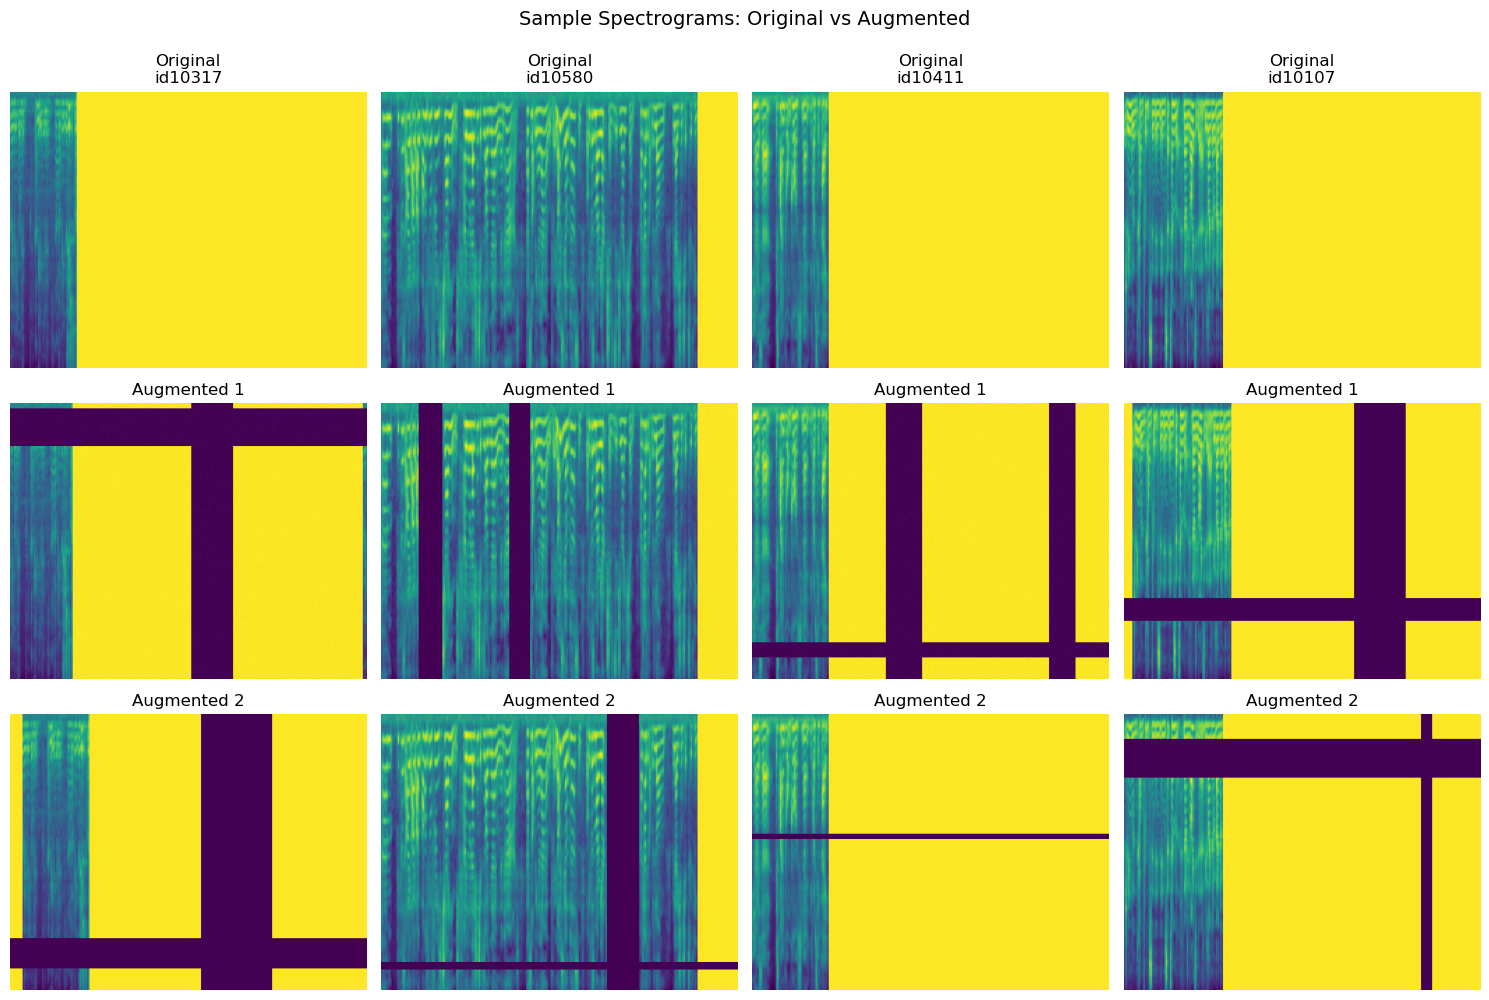

Sample spectrograms saved to sample_spectrograms.png
Note: Augmentations include SpecAugment (freq/time masking), noise, and time shifts


In [14]:
# Visualize spectrograms with and without augmentation
fig, axes = plt.subplots(3, 4, figsize=(15, 10))

idx_to_class = {v: k for k, v in class_to_idx.items()}

# Get a few samples without augmentation
no_aug_dataset = SpectrogramDataset(train_paths[:4], train_labels[:4], target_size=CONFIG['target_size'])

for i in range(4):
    spec, label = no_aug_dataset[i]
    speaker_id = idx_to_class[label]
    
    # Original
    axes[0, i].imshow(spec.squeeze().numpy(), cmap='viridis', aspect='auto')
    axes[0, i].set_title(f'Original\n{speaker_id}')
    axes[0, i].axis('off')
    
    # Augmented version 1
    aug_spec1 = train_augmentation(spec)
    axes[1, i].imshow(aug_spec1.squeeze().numpy(), cmap='viridis', aspect='auto')
    axes[1, i].set_title('Augmented 1')
    axes[1, i].axis('off')
    
    # Augmented version 2
    aug_spec2 = train_augmentation(spec)
    axes[2, i].imshow(aug_spec2.squeeze().numpy(), cmap='viridis', aspect='auto')
    axes[2, i].set_title('Augmented 2')
    axes[2, i].axis('off')

plt.suptitle('Sample Spectrograms: Original vs Augmented', fontsize=14, y=0.995)
plt.tight_layout()
plt.savefig('sample_spectrograms.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sample spectrograms saved to sample_spectrograms.png")
print("Note: Augmentations include SpecAugment (freq/time masking), noise, and time shifts")

## 10. VGG16-Lite Model Architecture

In [15]:
class VGGStyleCNN(nn.Module):
    """
    VGG16-Lite CNN for spectrogram classification
    Lighter architecture: [32, 32, 64, 64, 128, 128, 256] filters
    Input shape: (batch_size, 1, 256, 256)
    Output: (batch_size, num_classes)
    """
    
    def __init__(self, num_classes=605, input_channels=1, dropout=0.5):
        super(VGGStyleCNN, self).__init__()
        
        # Block 1: 2 Conv layers, 32 filters
        self.block1_conv1 = nn.Conv2d(input_channels, 32, kernel_size=3, padding=1)
        self.block1_conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.block1_pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.block1_bn = nn.BatchNorm2d(32)
        
        # Block 2: 2 Conv layers, 64 filters
        self.block2_conv1 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.block2_conv2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.block2_pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.block2_bn = nn.BatchNorm2d(64)
        
        # Block 3: 2 Conv layers, 128 filters
        self.block3_conv1 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.block3_conv2 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.block3_pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.block3_bn = nn.BatchNorm2d(128)
        
        # Block 4: 1 Conv layer, 256 filters
        self.block4_conv1 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.block4_pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.block4_bn = nn.BatchNorm2d(256)
        
        # Flatten and Dense layers
        self.flatten = nn.Flatten()
        # After 4 pooling layers: 256x256 -> 16x16
        # So output is 256 * 16 * 16 = 65536
        self.fc1 = nn.Linear(256 * 16 * 16, 512)
        self.dropout = nn.Dropout(dropout)
        self.fc1_bn = nn.BatchNorm1d(512)
        
        # Output layer
        self.predictions = nn.Linear(512, num_classes)
        
    def forward(self, x):
        # Block 1
        x = F.relu(self.block1_conv1(x))
        x = F.relu(self.block1_conv2(x))
        x = self.block1_pool(x)
        x = self.block1_bn(x)
        
        # Block 2
        x = F.relu(self.block2_conv1(x))
        x = F.relu(self.block2_conv2(x))
        x = self.block2_pool(x)
        x = self.block2_bn(x)
        
        # Block 3
        x = F.relu(self.block3_conv1(x))
        x = F.relu(self.block3_conv2(x))
        x = self.block3_pool(x)
        x = self.block3_bn(x)
        
        # Block 4
        x = F.relu(self.block4_conv1(x))
        x = self.block4_pool(x)
        x = self.block4_bn(x)
        
        # Flatten + Dense
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc1_bn(x)
        
        # Output
        x = self.predictions(x)
        return x

print('VGG16-Lite model defined')

VGG16-Lite model defined


## 14. Training Loop with Early Stopping

In [16]:
# Initialize model
num_classes = len(class_to_idx)
model = VGGStyleCNN(
    num_classes=num_classes,
    input_channels=1,
    dropout=CONFIG['dropout']
)

# Move model to GPU
model = model.to(device)

print(f"Model initialized with {num_classes} classes")
print(f"Model is on device: {next(model.parameters()).device}")

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Model initialized with 605 classes
Model is on device: cuda:0

Total parameters: 34,448,893
Trainable parameters: 34,448,893


## 11. Early Stopping Class

In [17]:
class EarlyStopping:
    """
    Early stopping to stop training when validation loss doesn't improve
    """
    
    def __init__(self, patience=7, min_delta=0.0, mode='min', verbose=True):
        """
        Args:
            patience: Number of epochs to wait before stopping
            min_delta: Minimum change to qualify as improvement
            mode: 'min' for loss, 'max' for accuracy
            verbose: Print messages
        """
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.verbose = verbose
        
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.best_epoch = 0
        
    def __call__(self, score, epoch):
        """
        Call this method after each epoch with validation metric
        
        Args:
            score: Validation metric (loss or accuracy)
            epoch: Current epoch number
        
        Returns:
            True if improved, False otherwise
        """
        # Convert score based on mode
        if self.mode == 'max':
            score = -score  # For maximization, negate the score
        
        # First epoch
        if self.best_score is None:
            self.best_score = score
            self.best_epoch = epoch
            return True
        
        # Check if improved
        if score < self.best_score - self.min_delta:
            self.best_score = score
            self.best_epoch = epoch
            self.counter = 0
            return True
        else:
            self.counter += 1
            if self.verbose:
                print(f"  EarlyStopping counter: {self.counter}/{self.patience}")
            
            if self.counter >= self.patience:
                self.early_stop = True
                if self.verbose:
                    print(f"\n  Early stopping triggered! Best epoch was {self.best_epoch}")
            
            return False

print("Early stopping class defined")

Early stopping class defined


## 12. Loss Function and Optimizer

In [18]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'])

# Learning rate scheduler (optional but recommended)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode='min', 
    factor=0.5, 
    patience=5 
)

print(f"Loss function: {criterion}")
print(f"Optimizer: {optimizer.__class__.__name__}")
print(f"Initial learning rate: {CONFIG['learning_rate']}")

Loss function: CrossEntropyLoss()
Optimizer: Adam
Initial learning rate: 0.0001


## 13. Training Functions

In [19]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    """
    Train the model for one epoch
    
    Returns:
        avg_loss: Average training loss
        accuracy: Training accuracy
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    progress_bar = tqdm(train_loader, desc='Training', leave=False)
    
    for batch_idx, (inputs, labels) in enumerate(progress_bar):
        try:
            # Move data to device
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            # Zero gradients
            optimizer.zero_grad()
            
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            # Backward pass
            loss.backward()
            
            # Gradient clipping for stability
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            
            # Statistics
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
            # Update progress bar
            progress_bar.set_postfix({
                'loss': running_loss / (batch_idx + 1),
                'acc': 100. * correct / total
            })
            
            # Clear cache periodically
            if batch_idx % 10 == 0:
                del inputs, outputs, loss
        
        except RuntimeError as e:
            print(f"\nError in batch {batch_idx}: {str(e)}")
            print("Skipping this batch and continuing...")
            continue
    
    avg_loss = running_loss / len(train_loader)
    accuracy = 100. * correct / total
    
    return avg_loss, accuracy


def validate(model, val_loader, criterion, device):
    """
    Validate the model
    
    Returns:
        avg_loss: Average validation loss
        accuracy: Validation accuracy
    """
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    progress_bar = tqdm(val_loader, desc='Validation', leave=False)
    
    with torch.no_grad():
        for batch_idx, (inputs, labels) in enumerate(progress_bar):
            # Move data to device
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            # Statistics
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
            # Update progress bar
            progress_bar.set_postfix({
                'loss': running_loss / (batch_idx + 1),
                'acc': 100. * correct / total
            })
    
    avg_loss = running_loss / len(val_loader)
    accuracy = 100. * correct / total
    
    return avg_loss, accuracy

## 14. Training Loop

In [15]:
# Training history
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'epoch_time': []
}

best_val_acc = 0.0
best_epoch = 0

# Initialize early stopping
early_stopping = EarlyStopping(
    patience=CONFIG['early_stopping_patience'],
    mode='min',  # Monitor validation loss
    verbose=True
)

print("Starting training with early stopping...\n")
print(f"Early stopping patience: {CONFIG['early_stopping_patience']} epochs")
print("=" * 80)


for epoch in range(CONFIG['num_epochs']):
    epoch_start_time = time.time()
    
    print(f"\nEpoch {epoch + 1}/{CONFIG['num_epochs']}")
    print("-" * 80)
    
    # Train
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    
    # Validate
    val_loss, val_acc = validate(
        model, val_loader, criterion, device
    )
    
    # Update learning rate scheduler
    scheduler.step(val_loss)
    
    epoch_time = time.time() - epoch_start_time
    
    # Save history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['epoch_time'].append(epoch_time)
    
    # Print epoch summary
    print(f"\nTrain Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")
    print(f"Epoch Time: {epoch_time/60:.2f} min | Est. remaining: {(CONFIG['num_epochs']-epoch-1)*epoch_time/3600:.2f} hours")
    
    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'val_loss': val_loss,
            'class_to_idx': class_to_idx,
            'config': CONFIG
        }, CONFIG['model_save_path'])
        print(f"✓ Best model saved! (Val Acc: {val_acc:.2f}%)")
    
    # Early stopping check
    early_stopping(val_loss, epoch + 1)
    
    if early_stopping.early_stop:
        print(f"\n⚠ Training stopped early at epoch {epoch + 1}")
        print(f"Best model was at epoch {best_epoch} with val accuracy {best_val_acc:.2f}%")
        break
    
    print("=" * 80)

print(f"\n\nTraining completed!")
print(f"Best validation accuracy: {best_val_acc:.2f}% (Epoch {best_epoch})")
print(f"Total epochs trained: {len(history['train_loss'])}")
print(f"Model saved to: {CONFIG['model_save_path']}")

Starting training with early stopping...

Early stopping patience: 7 epochs

Epoch 1/50
--------------------------------------------------------------------------------


Training:   0%|          | 0/607 [00:00<?, ?it/s]

Validation:   0%|          | 0/152 [00:00<?, ?it/s]


Train Loss: 6.0241 | Train Acc: 3.72%
Val Loss:   5.1976 | Val Acc:   11.70%
Epoch Time: 6.82 min | Est. remaining: 5.57 hours
✓ Best model saved! (Val Acc: 11.70%)

Epoch 2/50
--------------------------------------------------------------------------------


Training:   0%|          | 0/607 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/152 [00:00<?, ?it/s]


Train Loss: 0.1367 | Train Acc: 96.71%
Val Loss:   0.5776 | Val Acc:   86.16%
Epoch Time: 5.88 min | Est. remaining: 0.10 hours
  EarlyStopping counter: 4/7

Epoch 50/50
--------------------------------------------------------------------------------


Training:   0%|          | 0/607 [00:00<?, ?it/s]

Validation:   0%|          | 0/152 [00:00<?, ?it/s]


Train Loss: 0.1359 | Train Acc: 96.64%
Val Loss:   0.5938 | Val Acc:   85.91%
Epoch Time: 5.89 min | Est. remaining: 0.00 hours
  EarlyStopping counter: 5/7


Training completed!
Best validation accuracy: 86.60% (Epoch 45)
Total epochs trained: 50
Model saved to: voxceleb_cnn_lite_gpu.pth


## 15. Plot Training History

NameError: name 'history' is not defined

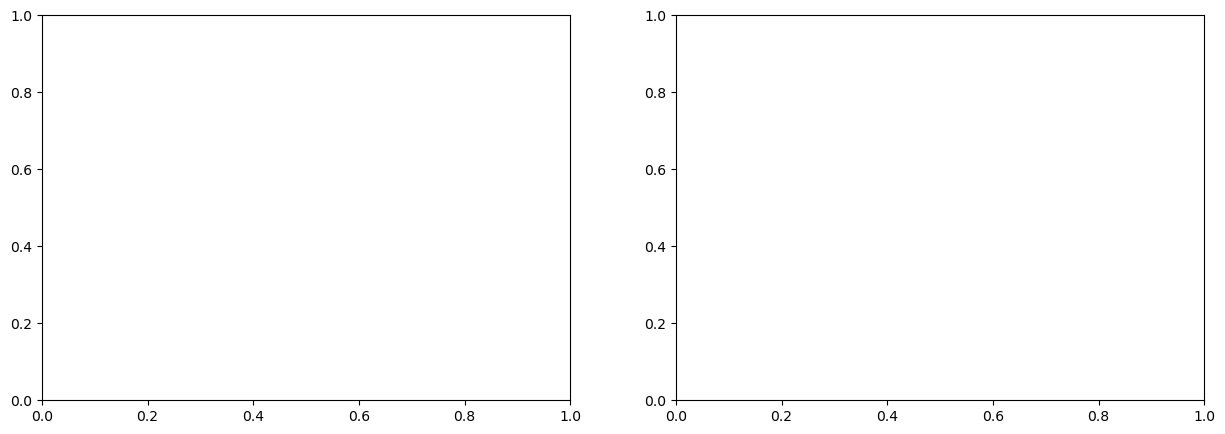

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot loss
axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history['val_loss'], label='Val Loss', marker='s')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot accuracy
axes[1].plot(history['train_acc'], label='Train Acc', marker='o')
axes[1].plot(history['val_acc'], label='Val Acc', marker='s')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_history_lite.png', dpi=150, bbox_inches='tight')
plt.show()

print("Training history plot saved to training_history_lite.png")

## 16. Save Training History

In [21]:
# Save history to JSON
with open('training_history_lite.json', 'w') as f:
    json.dump(history, f, indent=2)

print("Training history saved to training_history_lite.json")

# Print final statistics
print(f"\nFinal Training Statistics:")
print(f"  Final train accuracy: {history['train_acc'][-1]:.2f}%")
print(f"  Final val accuracy: {history['val_acc'][-1]:.2f}%")
print(f"  Best val accuracy: {best_val_acc:.2f}% (Epoch {best_epoch})")
print(f"  Average epoch time: {np.mean(history['epoch_time']):.2f}s")
print(f"  Total training time: {sum(history['epoch_time']) / 60:.2f} minutes")

NameError: name 'history' is not defined

## 17. Load Best Model for Inference

In [22]:
# Load the best saved model
checkpoint = torch.load(CONFIG['model_save_path'])
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f"Best model loaded from {CONFIG['model_save_path']}")
print(f"Model was saved at epoch {checkpoint['epoch'] + 1}")
print(f"Validation accuracy: {checkpoint['val_acc']:.2f}%")

Best model loaded from voxceleb_cnn_lite_gpu.pth
Model was saved at epoch 45
Validation accuracy: 86.60%


# Evaluation Metrics

In [24]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns

print("="*80)
print("EVALUATING MODEL ON VALIDATION SET")
print("="*80)

# Set model to evaluation mode
model.eval()

# Store predictions and true labels
all_preds = []
all_labels = []

# Disable gradient computation
with torch.no_grad():
    for spectrograms, labels in tqdm(val_loader, desc="Evaluating"):
        spectrograms = spectrograms.to(device)
        labels = labels.to(device)
        
        # Forward pass
        outputs = model(spectrograms)
        _, predicted = torch.max(outputs.data, 1)
        
        # Store predictions and labels
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Convert to numpy arrays
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Calculate overall accuracy
accuracy = 100 * np.mean(all_preds == all_labels)
print(f"\n✓ Overall Validation Accuracy: {accuracy:.2f}%")

# Calculate precision, recall, and F1 score
precision, recall, f1, support = precision_recall_fscore_support(
    all_labels, all_preds, average='weighted', zero_division=0
)

print("="*80)
print("WEIGHTED METRICS (Averaged across all classes)")
print("="*80)
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print("="*80)

# Also calculate macro-averaged metrics (unweighted average)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    all_labels, all_preds, average='macro', zero_division=0
)

print("\nMACRO METRICS (Unweighted average across all classes)")
print("="*80)
print(f"Precision: {precision_macro:.4f}")
print(f"Recall:    {recall_macro:.4f}")
print(f"F1 Score:  {f1_macro:.4f}")
print("="*80)

# Get per-class metrics for detailed analysis
print("\n" + "="*80)
print("PER-CLASS METRICS")
print("="*80)
print("\nNote: Showing metrics for classes with most samples in validation set\n")

# Calculate per-class metrics
precision_per_class, recall_per_class, f1_per_class, support_per_class = precision_recall_fscore_support(
    all_labels, all_preds, average=None, zero_division=0
)

# Create a DataFrame for better visualization
import pandas as pd
metrics_df = pd.DataFrame({
    'Class': range(len(support_per_class)),
    'Support': support_per_class,
    'Precision': precision_per_class,
    'Recall': recall_per_class,
    'F1-Score': f1_per_class
})

# Sort by support (most samples first) and show top 10
metrics_df_sorted = metrics_df.sort_values('Support', ascending=False).head(10)
print(metrics_df_sorted.to_string(index=False))

# Plot confusion matrix for a subset of classes (top 10 most frequent)
print("\n" + "="*80)
print("GENERATING CONFUSION MATRIX (Top 10 Classes)")
print("="*80)

# Get indices of top 10 most frequent classes
top_classes = metrics_df_sorted['Class'].values

# Filter predictions and labels for top classes
mask = np.isin(all_labels, top_classes)
filtered_labels = all_labels[mask]
filtered_preds = all_preds[mask]

# Create mapping for display
class_mapping = {old: new for new, old in enumerate(top_classes)}
remapped_labels = np.array([class_mapping[label] for label in filtered_labels])
remapped_preds = np.array([class_mapping[pred] for pred in filtered_preds])

# Compute confusion matrix
cm = confusion_matrix(remapped_labels, remapped_preds)

# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=top_classes, 
            yticklabels=top_classes,
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix (Top 10 Classes by Support)')
plt.ylabel('True Label (Class ID)')
plt.xlabel('Predicted Label (Class ID)')
plt.tight_layout()
plt.savefig('confusion_matrix_top10.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Confusion matrix saved to 'confusion_matrix_top10.png'")

# Summary statistics
print("\n" + "="*80)
print("SUMMARY STATISTICS")
print("="*80)
print(f"Total validation samples:     {len(all_labels)}")
print(f"Number of classes:            {len(np.unique(all_labels))}")
print(f"Correctly classified:         {np.sum(all_preds == all_labels)}")
print(f"Incorrectly classified:       {np.sum(all_preds != all_labels)}")
print(f"Overall Accuracy:             {accuracy:.2f}%")
print(f"Weighted Precision:           {precision:.4f}")
print(f"Weighted Recall:              {recall:.4f}")
print(f"Weighted F1 Score:            {f1:.4f}")
print("="*80)


EVALUATING MODEL ON VALIDATION SET


Evaluating:   0%|          | 0/152 [00:00<?, ?it/s]


✓ Overall Validation Accuracy: 86.60%
WEIGHTED METRICS (Averaged across all classes)
Precision: 0.8717
Recall:    0.8660
F1 Score:  0.8641

MACRO METRICS (Unweighted average across all classes)
Precision: 0.8645
Recall:    0.8323
F1 Score:  0.8415

PER-CLASS METRICS

Note: Showing metrics for classes with most samples in validation set

 Class  Support  Precision   Recall  F1-Score
    95      131   0.984615 0.977099  0.980843
    19      118   0.966942 0.991525  0.979079
   356       85   0.953488 0.964706  0.959064
   202       80   0.886364 0.975000  0.928571
   302       76   0.961039 0.973684  0.967320
   387       73   0.896104 0.945205  0.920000
   541       71   0.870130 0.943662  0.905405
   241       69   0.957746 0.985507  0.971429
   498       68   0.915493 0.955882  0.935252
   285       68   0.985294 0.985294  0.985294

GENERATING CONFUSION MATRIX (Top 10 Classes)


KeyError: np.int64(407)

## 18. Inference Example

Testing on: Spectograms\id10130\5hHu6Nuhj_4\00003.npy
True speaker: id10130 (Label: 129)

Top 5 Predictions:
--------------------------------------------------
✓ 1. Speaker: id10130 | Confidence: 90.07%
  2. Speaker: id10152 | Confidence: 3.86%
  3. Speaker: id10441 | Confidence: 0.71%
  4. Speaker: id10479 | Confidence: 0.62%
  5. Speaker: id10387 | Confidence: 0.56%


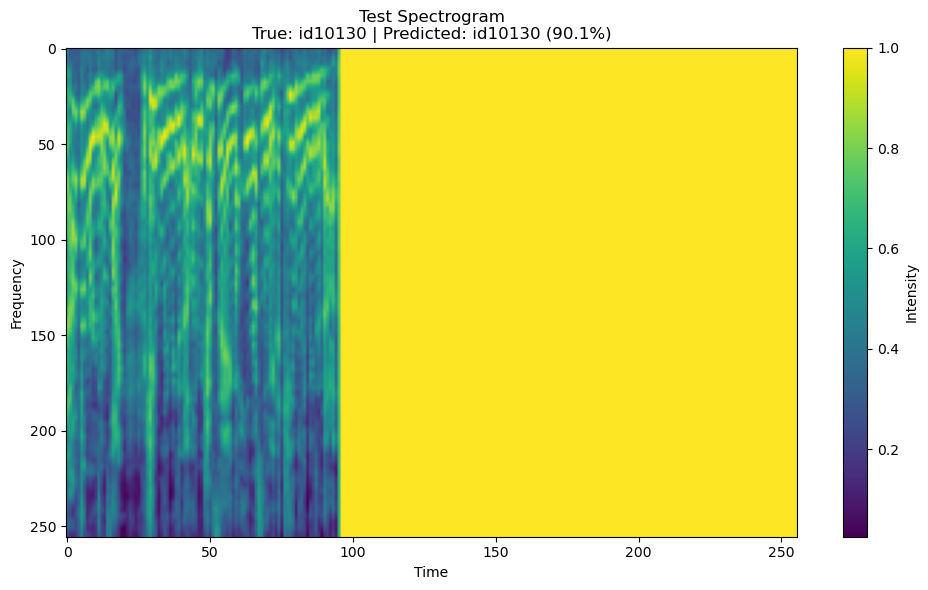


Inference example saved to inference_example.png


In [26]:
def predict_sample(model, spectrogram_path, class_to_idx, device, top_k=5):
    """
    Predict the speaker for a single spectrogram
    
    Args:
        model: Trained model
        spectrogram_path: Path to .npy spectrogram file
        class_to_idx: Class mapping dictionary
        device: Device to run inference on
        top_k: Number of top predictions to return
    
    Returns:
        predictions: List of (speaker_id, confidence) tuples
    """
    # Load and preprocess spectrogram
    spectrogram = np.load(spectrogram_path)
    
    if spectrogram.ndim == 1:
        size = int(np.sqrt(len(spectrogram)))
        spectrogram = spectrogram[:size*size].reshape(size, size)
    
    # Convert to tensor
    spectrogram = torch.FloatTensor(spectrogram).unsqueeze(0).unsqueeze(0)
    
    # Normalize
    if spectrogram.max() > spectrogram.min():
        spectrogram = (spectrogram - spectrogram.min()) / (spectrogram.max() - spectrogram.min())
    
    # Resize to target size (256x256)
    target_size = (256, 256)
    if spectrogram.shape[2:] != target_size:
        spectrogram = F.interpolate(
            spectrogram,
            size=target_size,
            mode='bilinear',
            align_corners=False
        )
    
    # Move to device
    spectrogram = spectrogram.to(device)
    
    # Inference
    model.eval()
    with torch.no_grad():
        output = model(spectrogram)
        probabilities = F.softmax(output, dim=1)
    
    # Get top-k predictions
    top_probs, top_indices = probabilities.topk(top_k, dim=1)
    
    # Convert to speaker IDs
    idx_to_class = {v: k for k, v in class_to_idx.items()}
    
    predictions = []
    for i in range(top_k):
        idx = top_indices[0][i].item()
        prob = top_probs[0][i].item()
        speaker_id = idx_to_class[idx]
        predictions.append((speaker_id, prob))
    
    return predictions, spectrogram.cpu().squeeze()


# Test on a random validation sample
random_idx = np.random.randint(len(val_paths))
test_path = val_paths[random_idx]
true_label = val_labels[random_idx]

idx_to_class = {v: k for k, v in class_to_idx.items()}
true_speaker = idx_to_class[true_label]

print(f"Testing on: {test_path}")
print(f"True speaker: {true_speaker} (Label: {true_label})\n")

predictions, spec = predict_sample(model, test_path, class_to_idx, device, top_k=5)

print("Top 5 Predictions:")
print("-" * 50)
for i, (speaker_id, confidence) in enumerate(predictions, 1):
    marker = "✓" if speaker_id == true_speaker else " "
    print(f"{marker} {i}. Speaker: {speaker_id} | Confidence: {confidence*100:.2f}%")

# Visualize the test spectrogram
plt.figure(figsize=(10, 6))
plt.imshow(spec.numpy(), cmap='viridis', aspect='auto')
plt.colorbar(label='Intensity')
plt.title(f'Test Spectrogram\nTrue: {true_speaker} | Predicted: {predictions[0][0]} ({predictions[0][1]*100:.1f}%)')
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('inference_example.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nInference example saved to inference_example.png")

## 19. Model Summary

In [20]:
print("\n" + "="*80)
print("TRAINING SUMMARY")
print("="*80)
print(f"\nDataset:")
print(f"  Total classes: {num_classes}")
print(f"  Training samples: {len(train_paths)}")
print(f"  Validation samples: {len(val_paths)}")
print(f"\nModel:")
print(f"  Architecture: VGG-Style CNN")
print(f"  Total parameters: {total_params:,}")
print(f"  Device: {device} (CPU)")
print(f"\nTraining Configuration:")
print(f"  Epochs: {CONFIG['num_epochs']}")
print(f"  Batch size: {CONFIG['batch_size']}")
print(f"  Learning rate: {CONFIG['learning_rate']}")
print(f"  Dropout: {CONFIG['dropout']}")
print(f"\nResults:")
print(f"  Best validation accuracy: {best_val_acc:.2f}% (Epoch {best_epoch})")
print(f"  Final train accuracy: {history['train_acc'][-1]:.2f}%")
print(f"  Final val accuracy: {history['val_acc'][-1]:.2f}%")
print(f"  Total training time: {sum(history['epoch_time']) / 60:.2f} minutes")
print(f"\nSaved Files:")
print(f"  Model: {CONFIG['model_save_path']}")
print(f"  Class mapping: class_to_idx.json")
print(f"  Training history: training_history.json")
print(f"  Plots: training_history.png, sample_spectrograms.png, inference_example.png")
print("\n" + "="*80)


TRAINING SUMMARY

Dataset:
  Total classes: 605
  Training samples: 58212
  Validation samples: 14554

Model:
  Architecture: VGG-Style CNN
  Total parameters: 34,448,893
  Device: cuda (CPU)

Training Configuration:
  Epochs: 50
  Batch size: 96
  Learning rate: 0.0001
  Dropout: 0.5

Results:
  Best validation accuracy: 86.60% (Epoch 45)
  Final train accuracy: 96.64%
  Final val accuracy: 85.91%
  Total training time: 318.44 minutes

Saved Files:
  Model: voxceleb_cnn_lite_gpu.pth
  Class mapping: class_to_idx.json
  Training history: training_history.json
  Plots: training_history.png, sample_spectrograms.png, inference_example.png

